# 05 — CNN para Classificação

Treinamento de uma CNN simples para classificar os espectrogramas (já com CLAHE + contraste, em `mod_spectograms`) nas quatro classes: `ictal`, `normal`, `pos_ictal` e `pre_ictal`. A divisão treino/validação segue o `splits.csv`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1795012591.584714    9382 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']
(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [ ]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3))) # Convolucao 2D
model.add(MaxPooling2D((2, 2))) # Camada de coarsen
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))

model.summary()

/home/orlandomota/miniconda3/envs/epilepsy-detection/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1795012595.207989    9382 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5309 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:06:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30


W0000 00:00:1795012596.119756    9382 cpu_allocator_impl.cc:82] Allocation of 60211200 exceeds 10% of free system memory.
W0000 00:00:1795012596.183976    9382 cpu_allocator_impl.cc:82] Allocation of 60211200 exceeds 10% of free system memory.
W0000 00:00:1795012597.051433    9637 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.
W0000 00:00:1795012597.051448    9639 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.
W0000 00:00:1795012597.051468    9634 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.
I0000 00:00:1795012597.068106    9579 service.cc:153] XLA service 0x723a58005560 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795012597.068124    9579 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3070, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795012597.103163    

4/4 - 12s - 3s/step - accuracy: 0.1800 - loss: 1.5628 - val_accuracy: 0.3000 - val_loss: 1.3538
Epoch 2/30
4/4 - 0s - 46ms/step - accuracy: 0.3600 - loss: 1.3677 - val_accuracy: 0.3500 - val_loss: 1.3639
Epoch 3/30
4/4 - 0s - 44ms/step - accuracy: 0.3500 - loss: 1.3666 - val_accuracy: 0.4000 - val_loss: 1.3113
Epoch 4/30
4/4 - 0s - 44ms/step - accuracy: 0.4400 - loss: 1.3070 - val_accuracy: 0.4500 - val_loss: 1.1978
Epoch 5/30
4/4 - 0s - 43ms/step - accuracy: 0.4400 - loss: 1.2478 - val_accuracy: 0.5000 - val_loss: 1.1735
Epoch 6/30
4/4 - 0s - 43ms/step - accuracy: 0.4400 - loss: 1.1997 - val_accuracy: 0.4500 - val_loss: 1.1917
Epoch 7/30
4/4 - 0s - 44ms/step - accuracy: 0.5300 - loss: 1.1168 - val_accuracy: 0.4000 - val_loss: 1.1682
Epoch 8/30
4/4 - 0s - 43ms/step - accuracy: 0.5800 - loss: 1.0036 - val_accuracy: 0.4500 - val_loss: 1.1297
Epoch 9/30
4/4 - 0s - 44ms/step - accuracy: 0.5900 - loss: 0.8859 - val_accuracy: 0.4000 - val_loss: 1.1928
Epoch 10/30
4/4 - 0s - 43ms/step - accur

In [5]:
print(f"Acurácia final de treinamento: {history.history['accuracy'][-1]:.4f}")
print(f"Acurácia final de validação:   {history.history['val_accuracy'][-1]:.4f}")
print(f"Loss final de treinamento:     {history.history['loss'][-1]:.4f}")
print(f"Loss final de validação:       {history.history['val_loss'][-1]:.4f}")

Acurácia final de treinamento: 0.9700
Acurácia final de validação:   0.4000
Loss final de treinamento:     0.0671
Loss final de validação:       3.6251


## Gráficos

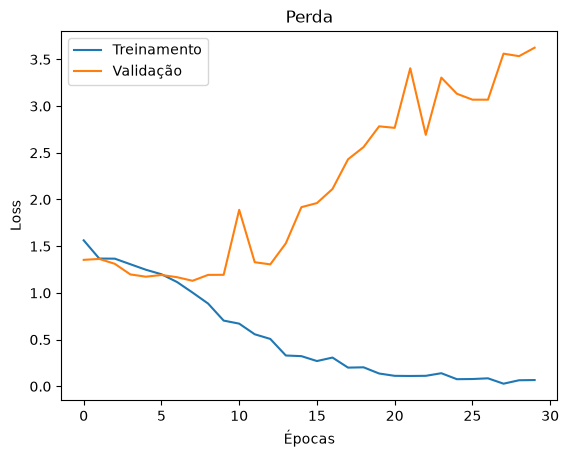

In [6]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Perda')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend(['Treinamento', 'Validação'])
plt.show()

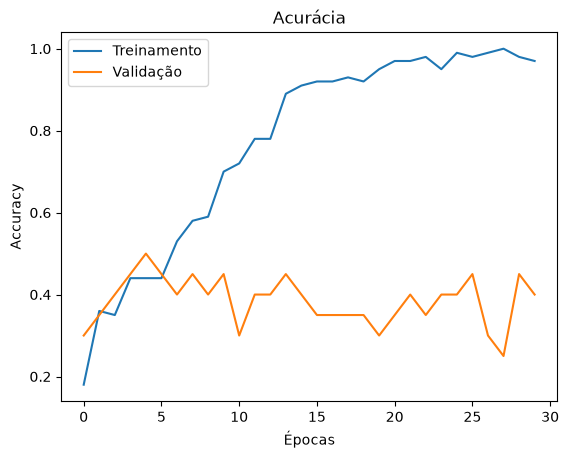

In [7]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Acurácia')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend(['Treinamento', 'Validação'])
plt.show()

## Resultados

| Métrica | Valor |
|---|---|
| Acurácia final de treinamento | 0.69 |
| Acurácia final de validação | 0.45 |
| Loss final de treinamento | 0.70 |
| Loss final de validação | 1.17 |

A loss de treinamento cai de forma contínua (1.56 → 0.70) e a acurácia de treino sobe até 69%, então a rede está aprendendo os dados de treino. Na validação a loss cai bem menos (1.35 → 1.14 na 8ª época) e a acurácia oscila entre 30% e 50%, não muito acima do acaso para 4 classes (25%). A distância entre as curvas de treino e validação, que só aumenta, indica overfitting: a rede tem cerca de 11 milhões de parâmetros para apenas 100 imagens de treino. Com só 20 imagens de validação, cada imagem vale 5 pontos percentuais, o que explica a oscilação da curva.

## Salvando o modelo

In [8]:
model.save(PROJECT_ROOT / 'models' / 'modelo_cnn.keras')

## Perguntas

**O que faz o otimizador Adam?**
Ele ajusta os pesos da rede a partir do gradiente da loss, mas com uma taxa de aprendizado adaptativa para cada peso. Combina o momentum (média dos gradientes anteriores, que suaviza a direção da atualização) com o RMSProp (média dos gradientes ao quadrado, que regula o tamanho do passo). Na prática converge rápido e funciona bem sem muito ajuste de hiperparâmetros.

**Por que a camada final utiliza Softmax?**
Porque é um problema multiclasse com 4 classes mutuamente exclusivas. A softmax transforma as 4 saídas em probabilidades que somam 1, e a classe prevista é a de maior probabilidade. Isso também casa com a `sparse_categorical_crossentropy`, que espera uma distribuição de probabilidade na saída.

**Quantas camadas convolucionais existem?**
3 (`Conv2D` com 32, 64 e 128 filtros).

**Quantas camadas de pooling existem?**
3 (`MaxPooling2D` 2x2 após cada convolução).

**Quantos parâmetros possui a rede?**
11.169.476 parâmetros treináveis:

| Camada | Saída | Parâmetros |
|---|---|---|
| Conv2D (32) | 222x222x32 | 3·3·3·32 + 32 = 896 |
| MaxPooling2D | 111x111x32 | 0 |
| Conv2D (64) | 109x109x64 | 3·3·32·64 + 64 = 18.496 |
| MaxPooling2D | 54x54x64 | 0 |
| Conv2D (128) | 52x52x128 | 3·3·64·128 + 128 = 73.856 |
| MaxPooling2D | 26x26x128 | 0 |
| Flatten | 86.528 | 0 |
| Dense (128) | 128 | 86.528·128 + 128 = 11.075.712 |
| Dropout | 128 | 0 |
| Dense (4) | 4 | 128·4 + 4 = 516 |

Quase tudo (99%) está na primeira camada densa, por causa do Flatten de 86.528 valores.

**Qual camada é responsável pela classificação final?**
A última `Dense(4, activation='softmax')`, que gera a probabilidade de cada uma das 4 classes.